# Семинар 8. Предобученные и современные трансформеры

В ноутбуке показаны загрузка IMDb, токенизация, обучение и оценка BERT, RoBERTa и DistilBERT. Затем разобраны реализации MHA, MQA, GQA, MoE и RoPE.

Для обучения рекомендуется GPU. Первый запуск требует доступа к интернету для загрузки данных и моделей. После установки или обновления библиотек перезапустите ядро и продолжите со следующей ячейки.

### Transfer learning

Рассмотрим обучение модели на небольшом объеме данных для сложной задачи, например NER. Если обучать модель с нуля, то, вероятнее всего, мы получим неблагоприятный с точки зрения качества исход: не имея качественных контекстуальных векторных представлений токенов, нам при наличии лишь малой обучающей выборки не удастся добиться успеха по классификации токенов.

На помощь приходит **transfer learning**. Предлагается рассматривать обучение моделей на нескольких этапах:
1. Этап предобучения (pretrain). Обучение происходит на общую задачу и на большом объеме данных. Очень часто не требуется наличия разметки данных либо требуется минимальная разметка. Целью является обучение каким-либо общим способностям (например, ResNet после предобучения способен выдавать довольно качественные признаковые описания изображений).
2. Этап дообучения (FineTuning). Вернемся к исходной задаче. Теперь, когда мы имеем предобученную модель с необходимыми нам свойствами, ее можно дообучить на имеющейся малой выборке, достигнув уже достаточно высокого качества.
3. Linear Probing. В идеале, нам достаточно обучить, например, только голову классификации, не размораживая предобученную модель. Если векторные представления объектов достаточно информативны, то в таком случае также можно достичь довольно хорошего качества. На практике последние 2 этапа комбинируют: можно разморозить голову и часть параметров предобученной модели, достигнув качества, сопоставимого со случаем полной разморозки всей модели при сильном ускорении процесса обучения.

## BERT

В отличие от общей схемы трансформера в данном случае архитектура модели содержит только энкодер-часть. Предположим, нам хотелось бы, чтобы языковая модель выдавала векторные представления токенов и текста, пригодные для использования в задачах классификации текста и токенов, NER, задаче получения качественных эмбеддингов. Таким образом, хотелось бы наличия у модели двух ключевых свойств:

1. Умение моделировать язык на уровне контекста (гипотеза дистрибутивности).
2. Умение выдавать эмбеддинг текста.

Тем самым мы приходим к стандартным задачам претрейна многих классических моделей на основе архитектуры трансформера:

1. Masked language modeling. Часть токенов исходных текстов заменялась на специальный токен [MASK], с помощью механизма внимания требуется восстановить потерянные токены.
2. Next sentence prediction. Для упорядоченной пары предложений требуется определить, является второе предложение продолжением первого.

При рассмотрении данной и следующих моделей для нас наиболее важен этап их предобучения, так как именно он, наряду с архитектурой модели, определяет возможности для дообучения и применения модели в определенных задачах.

**Вопросы:**
1. Как трансформеру решать задачу Masked language modeling?
2. Должен ли эмбеддинг токена для маскирования [MASK] быть обучаемым? Если нет, то чему он равен?

#### Ответы и пояснения

1. Masked language modeling. С помощью механизма внимания энкодер вычислял контекстные векторные представления соответствующих токенов, подавая их в классификатор по токенам. Тем самым модель обучается моделированию языка и генерации векторных представлений токенов по контексту.
2. Next sentence prediction. Два сегмента соединяются в последовательность [CLS] A [SEP] B [SEP]. Контекстное представление начального токена [CLS] подается в бинарный классификатор, который предсказывает, является ли второе предложение следующим по смыслу за первым. Тем самым модель обучается моделированию языка на уровне предложений, а векторное представление [CLS] токена может быть использовано как векторное представление текста.

В исходной реализации BERT варианты маскирования создавались при подготовке данных; один текст мог иметь несколько заранее подготовленных вариантов. Для токенизации использовался WordPiece.

#### Вопрос

Как в таком случае применять предобученный BERT в задаче классификации предложений?

In [ ]:
%pip install --disable-pip-version-check -q --upgrade --upgrade-strategy only-if-needed \
    "transformers[torch]==5.20.2" "datasets==4.8.5" \
    "huggingface-hub==1.33.0" "evaluate==0.4.6" \
    "accelerate==1.15.0" "scikit-learn==1.7.2" \
    "pyarrow==23.0.1" "fsspec[http]==2025.12.0" \
    "ipywidgets>=8.1,<9"

Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install --disable-pip-version-check -q "matplotlib>=3.8,<4"
%matplotlib inline


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import torch
from torch import nn
import evaluate
from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding, set_seed
)
from functools import partial

set_seed(42)

W1022 20:39:57.409000 83123 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [ ]:
dataset = load_dataset("stanfordnlp/imdb", revision="e6281661ce1c48d982bc483cf8a173c1bbeb5d31")
del dataset['unsupervised']
shuffled_train = dataset["train"].shuffle(seed=42)
dataset["train"] = shuffled_train.select(range(1000))
# Validation выделена из оставшейся обучающей части IMDb.
dataset["validation"] = shuffled_train.select(range(1000, 2000))
dataset["test"] = dataset["test"].shuffle(seed=42).select(range(1000))
del shuffled_train
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1000
    })
})

In [ ]:
dataset['train'][0]

{'text': 'There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier\'s plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compare, to judge, to evaluate. How about just enjoying? Funny thing too, people writing Fortier looks American but, on the other hand, arguing they prefer American series (!!!). Maybe it\'s the language, or the spirit, but I think this series is more English than American. By the way, the actors are really good and funny. The acting is not superficial at all...',
 'label': 1}

In [ ]:
def preprocess(examples, tokenizer):
    return tokenizer(examples["text"], truncation=True, padding=False)
tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-uncased",
    revision="86b5e0934494bd15c9632b12f734a8a67f723594",
)
tokenized_dataset = dataset.map(partial(preprocess, tokenizer=tokenizer),
                                batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [ ]:
accuracy = evaluate.load("accuracy")
precision = evaluate.load("precision")
recall = evaluate.load("recall")
f1 = evaluate.load("f1")

In [ ]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {
        'accuracy': accuracy.compute(predictions=predictions, references=labels)['accuracy'],
        'precision': precision.compute(predictions=predictions, references=labels,
                                       average='binary', zero_division=0)['precision'],  # binary для 2 классов
        'recall': recall.compute(predictions=predictions, references=labels,
                                 average='binary', zero_division=0)['recall'],
        'f1': f1.compute(predictions=predictions, references=labels,
                         average='binary')['f1']
    }

In [ ]:
set_seed(42)
bert = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    revision="86b5e0934494bd15c9632b12f734a8a67f723594",
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1}
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
bert

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

In [ ]:
def parameters_count(model):
  return sum([p.numel() for p in model.parameters()])

In [ ]:
print(f"BERT parameters count: {parameters_count(bert):,}")

BERT parameters count: 109,483,778


In [ ]:
training_args = TrainingArguments(
    output_dir="checkpoints/bert",
    seed=42,
    data_seed=42,
    save_total_limit=1,
    dataloader_pin_memory=torch.cuda.is_available(),
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    metric_for_best_model="f1",
    report_to="none"
)

trainer = Trainer(
    model=bert,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [ ]:
trainer.train()
test_metrics_bert = trainer.evaluate(tokenized_dataset["test"], metric_key_prefix="test")
test_metrics_bert

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.530599,0.335915,0.871000,0.853974,0.902344,0.877493
2,0.211994,0.348712,0.893000,0.874307,0.923828,0.898386
3,0.114893,0.349238,0.904000,0.895437,0.919922,0.907514


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.114893,0.444330,3,0.881000,0.854127,0.911885,0.882061


{'test_loss': 0.4443303942680359,
 'test_accuracy': 0.881,
 'test_precision': 0.8541266794625719,
 'test_recall': 0.9118852459016393,
 'test_f1': 0.8820614469772051}

In [ ]:
import gc
del trainer, bert
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
if torch.backends.mps.is_available():
    torch.mps.empty_cache()

## RoBERTa

Тем не менее, методология предобучения BERT содержала определенные недостатки, которые стремились устранить авторы RoBERTa. **(?)** Как вы думаете, какие именно?

#### Ответ

Рассмотрим, какие нововведения предлагают авторы и с какой целью.
1. Static masking vs dynamic masking. В исходном BERT варианты маскирования создавались заранее: данные дублировались с разными масками. В RoBERTa маскирование выполняется динамически при подаче последовательности в модель.
2. Авторы статьи обнаружили, что обучение на задачу Next Sentence Prediction необязательно. Вместо этого предлагается подавать на вход предложения, сэмплируемые из документов корпуса, причем лучше брать их ровно из 1 документа.
3. Авторы исследуют большие батчи: 256, 2000 и 8000 последовательностей с соответствующим подбором learning rate. В итоговых экспериментах используется батч из 8000 последовательностей.
4. Также предлагается использовать BPE-токенизацию на уровне байтов вместо WordPiece в BERT. Базовый алфавит из байтов позволяет кодировать произвольный входной текст без неизвестных символов.

#### Дообучение RoBERTa

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(
    "roberta-base",
    revision="e2da8e2f811d1448a5b465c236feacd80ffbac7b",
)
tokenized_dataset = dataset.map(partial(preprocess, tokenizer=tokenizer),
                                batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [ ]:
set_seed(42)
roberta = AutoModelForSequenceClassification.from_pretrained(
    "roberta-base",
    revision="e2da8e2f811d1448a5b465c236feacd80ffbac7b",
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1}
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
roberta

RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
  

In [ ]:
print(f"Roberta parameters count: {parameters_count(roberta):,}")

Roberta parameters count: 124,647,170


In [ ]:
training_args = TrainingArguments(
    output_dir="checkpoints/roberta",
    seed=42,
    data_seed=42,
    save_total_limit=1,
    dataloader_pin_memory=torch.cuda.is_available(),
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    metric_for_best_model="f1",
    report_to="none"
)

trainer = Trainer(
    model=roberta,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)
trainer.train()
test_metrics_roberta = trainer.evaluate(tokenized_dataset["test"], metric_key_prefix="test")
test_metrics_roberta

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.475421,0.260149,0.926000,0.952479,0.900391,0.925703
2,0.245781,0.277983,0.935000,0.925714,0.949219,0.937319
3,0.124543,0.309165,0.930000,0.900362,0.970703,0.934211


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.124543,0.392278,3,0.911000,0.870130,0.961066,0.913340


{'test_loss': 0.3922783434391022,
 'test_accuracy': 0.911,
 'test_precision': 0.8701298701298701,
 'test_recall': 0.9610655737704918,
 'test_f1': 0.9133398247322297}

In [ ]:
del trainer, roberta
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
if torch.backends.mps.is_available():
    torch.mps.empty_cache()

## DistilBERT

Зачастую требуется найти баланс между качеством модели на решаемой задаче и ее скоростью обучения и инференса. Предположим, у нас есть обученная модель, позволяющая достигать высокого качества на поставленной задаче (teacher), однако в реальном мире хотелось бы применять более компактную по размерам ее версию (ученик). Целью дистилляции знаний является получение более компактной модели (ученика), качество и поведение которой как можно более сопоставимо с исходной (учителем).

В рамках дистилляции помимо обучения на основную задачу ученик также может учиться следующему:
1. Обучение на hard-предсказания учителя - учимся повторять предсказания модели-учителя.
2. Обучение на soft-предсказания учителя - учимся предсказывать распределения вероятностей учителя для классов.
3. Обучение на сходство промежуточных представлений ученика и учителя.

Авторы DistilBERT предлагают сократить число слоев модели вдвое, инициализируя их соответствующими параметрами из BERT, стартуя с приближения к дистиллируемой модели. Далее предобучение производится с функцией потерь из 3 основных компонентов:
1. Функция потерь для задачи MLM. Задача NSP игнорируется по аналогии с RoBERTa.
2. Лосс дистилляции $L_{ce} = -\sum_i t_i\log(s_i)$, где $t_i, s_i$ - вероятности, выдаваемые учителем и учеником, соответственно. То есть мы пытаемся воспроизвести поведение учителя с точки зрения предсказания вероятностей путем максимизации правдоподобия ученика с усреднением по распределениям, выдаваемым учителя. Этот подход именуется soft-label KD и является мягким ответом hard-label KD, где в правдоподобии берутся только те классы, вероятности которых у учителя наибольшие (hard-предсказания). В рассматриваемом подходе мы регуляризуем дистилляцию и пытаемся выучивать именно распределения учителя, а не просто hard-предсказания. Отметим также, что для оптимизации могут брать распределения учителя не полностью, а только top-k вероятностей. Кроме того, чтобы обучение не выродилось в hard-подход, при вычислении вероятностей учителем и учеником используется софтмакс с температурой:
$$p_i = \frac{exp(z_i/T)}{\sum_j exp(z_j/T)}$$
3. Косинусное сходство между скрытыми векторными представлениям учителя и ученика. Тем самым мы также моделируем скрытые представления учителя.

В экспериментах статьи DistilBERT сохраняет около **97% среднего результата BERT на GLUE**, содержит примерно **на 40% меньше параметров** и работает **на 60% быстрее** в условиях измерений авторов. [Sanh et al.](https://arxiv.org/abs/1910.01108).

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased",
    revision="12040accade4e8a0f71eabdb258fecc2e7e948be",
)
tokenized_dataset = dataset.map(partial(preprocess, tokenizer=tokenizer),
                                batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [ ]:
set_seed(42)
distilbert = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    revision="12040accade4e8a0f71eabdb258fecc2e7e948be",
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1}
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
distilbert

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [ ]:
print(f"DistilBert parameters count: {parameters_count(distilbert):,}")

DistilBert parameters count: 66,955,010


In [ ]:
training_args = TrainingArguments(
    output_dir="checkpoints/distilbert",
    seed=42,
    data_seed=42,
    save_total_limit=1,
    dataloader_pin_memory=torch.cuda.is_available(),
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    metric_for_best_model="f1",
    report_to="none"
)

trainer = Trainer(
    model=distilbert,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)
trainer.train()
test_metrics_distilbert = trainer.evaluate(tokenized_dataset["test"], metric_key_prefix="test")
test_metrics_distilbert

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.571322,0.363128,0.856000,0.901747,0.806641,0.851546
2,0.257741,0.282060,0.892000,0.904000,0.882812,0.893281
3,0.113258,0.316179,0.896000,0.887833,0.912109,0.899807


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.113258,0.354721,3,0.883000,0.860194,0.907787,0.883350


{'test_loss': 0.3547208309173584,
 'test_accuracy': 0.883,
 'test_precision': 0.8601941747572815,
 'test_recall': 0.9077868852459017,
 'test_f1': 0.8833499501495513}

In [ ]:
del trainer, distilbert
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
if torch.backends.mps.is_available():
    torch.mps.empty_cache()

## Реализации attention

### KV-cache для LLM

Механизм внимания принимает на вход последовательность токенов и для каждого из них строит три вектора: **запрос** (Query), **ключ** (Key) и **значение** (Value). Формально, имея матрицы $Q$, $K$, $V \in \mathbb{R}^{n \times d}$, выход attention вычисляется как:

$$
SoftMax(\frac{Q K^T \oplus mask}{\sqrt{d}}) V
$$

Здесь $\oplus mask$ - это прибавление маски: для декодера используется верхнетреугольная матрица, которая обнуляет веса будущих токенов, не позволяя позиции $i$ «смотреть» на позиции $j > i$. Деление на $\sqrt{d}$ нормирует скалярные произведения и стабилизирует градиенты.

Теперь рассмотрим инференс. Языковая модель - авторегрессионная: на каждом шаге она принимает уже сгенерированный префикс и предсказывает **один следующий токен**. Если к текущему моменту в контексте $n$ токенов, модель снова прогоняет весь attention: строит $Q$, $K$, $V$ для всех $n$ позиций, перемножает $QK^T$ - это $O(n^2d)$ операций для одной головы размерности $d$ - и получает выход.

Затем добавляется новый токен, контекст становится длиной $n+1$, и все повторяется заново. При длинных последовательностях это катастрофически дорого: большая часть вычислений просто **воспроизводит то, что уже было посчитано на предыдущем шаге**.



Заметим ключевое: в авторегрессионном декодере с причинной маской в режиме инференса предыдущие позиции не видят добавленный токен. Поэтому их состояния и проекции $Q$, $K$, $V$ не меняются. Значит, нам не нужно пересчитывать $K$ и $V$ для всего префикса - достаточно **закэшировать** их после первого прохода и на каждом следующем шаге досчитывать только одну новую строку.

Именно это и делает **KV-cache**: мы храним таблицы ключей и значений для всех уже обработанных позиций и на шаге $n+1$ вычисляем $K_{n+1}$, $V_{n+1}$ только для нового токена, а затем конкатенируем их с кэшем. Запрос $Q$ при этом нужен лишь для последней позиции - единственной, выход которой нас интересует.


In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

### MHA

**Вопрос:** Почему мы перешли к MHA?

#### Ответ

Разные головы могут выучиваться детектировать разные отношения в тексте (синтаксические и семантические).

#### Multi-Head self-attention

Пусть у нас есть эмбеддинги $X \in \mathbb{R}^{L \times D}$
и маска $mask \in \{0, -\infty\}^{L \times L}$

$mask_{i, j} = -\infty$, если для вычисления attention score для i-го токена нельзя использовать j-й токен. В формулах маска аддитивная: 0 для разрешенных позиций и $-\infty$ для запрещенных. В реализациях ниже маска бинарная: 1 разрешает позицию, 0 запрещает ее.

Мы разбиваем пространство $D$ на $h$ голов: $D = h \times d$

Прогоняем через проекции для каждой головы и получаем:

$$
Q^h = \{q_i = X W_i^Q \in \mathbb{R}^{L \times d}\}_{i=1}^{h}
$$
$$
K^h = \{k_i = X W_i^K \in \mathbb{R}^{L \times d}\}_{i=1}^{h}
$$
$$
V^h = \{v_i = X W_i^V \in \mathbb{R}^{L \times d}\}_{i=1}^{h}
$$

$W_i^Q, W_i^K, W_i^V \in \mathbb{R}^{D \times d}$ - обучаемые параметры $\forall i = 1,..., h$.

Для каждой головы применяем dot-product attention:

$$
a_i = DotProductAttention(q_i, k_i, v_i, mask) = SoftMax(\frac{q_i k_i^T \oplus mask}{\sqrt{d}}) v_i \in \mathbb{R}^{L \times d}
$$

Полученные выходы голов конкатенируем и умножаем на обучаемый параметр $W^O$:

$$
A = Concat(\{a_i\}_{i=1}^{h}) W^O \text{ - финальный результат MHA}
$$

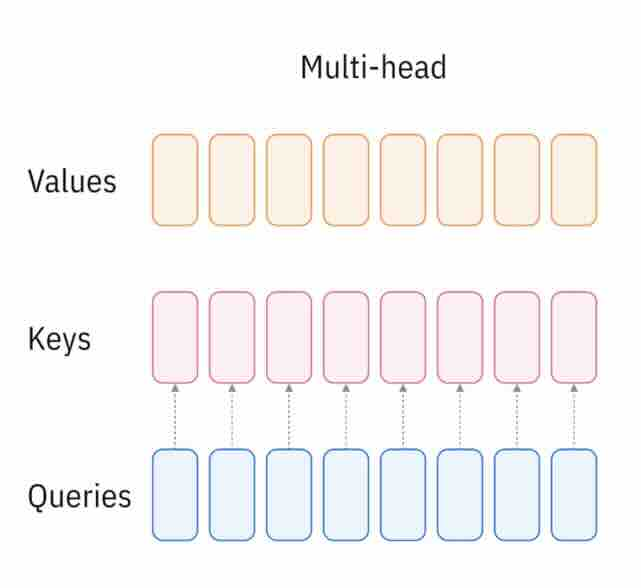

Схема: IBM. Метод: [Ainslie et al., 2023](https://arxiv.org/abs/2305.13245).

#### Реализация MHA

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        """
        Multi-Head Attention механизм

        Args:
            d_model: размерность модели (в наших вычислениях это D)
            num_heads: количество голов внимания (в наших вычислениях это h)
        """
        super(MultiHeadAttention, self).__init__()

        assert d_model % num_heads == 0, "d_model должен делиться на num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads  # размерность каждой головы

        # Линейные слои для Q, K, V
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)

        # Выходной линейный слой
        self.W_o = nn.Linear(d_model, d_model, bias=False)

    def forward(self, query, key, value, mask=None):
        """
        Forward pass для Multi-Head Attention

        Args:
            query: тензор [batch_size, seq_len_q, d_model]
            key: тензор [batch_size, seq_len_k, d_model]
            value: тензор [batch_size, seq_len_v, d_model]
            mask: опциональная маска [batch_size, 1, seq_len_q, seq_len_k]

        Returns:
            output: тензор [batch_size, seq_len_q, d_model]
            attention_weights: тензор [batch_size, num_heads, seq_len_q, seq_len_k]
        """
        batch_size = query.size(0)
        seq_len_q = query.size(1)
        seq_len_k = key.size(1)

        # Применяем линейные преобразования: [batch_size, seq_len, d_model]
        Q = self.W_q(query)
        K = self.W_k(key)
        V = self.W_v(value)

        # Разбиваем на головы: [batch_size, seq_len, num_heads, d_k]
        Q = Q.view(batch_size, seq_len_q, self.num_heads, self.d_k)
        K = K.view(batch_size, seq_len_k, self.num_heads, self.d_k)
        V = V.view(batch_size, seq_len_k, self.num_heads, self.d_k)

        # Transpose для удобства: [batch_size, num_heads, seq_len, d_k]
        Q = Q.transpose(1, 2)
        K = K.transpose(1, 2)
        V = V.transpose(1, 2)

        # Вычисляем scaled dot-product attention
        # scores: [batch_size, num_heads, seq_len_q, seq_len_k]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)

        # Применяем маску (если есть)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        # Применяем softmax
        attention_weights = torch.softmax(scores, dim=-1)

        # Умножаем на V: [batch_size, num_heads, seq_len_q, d_k]
        attn_output = torch.matmul(attention_weights, V)

        # Объединяем головы: [batch_size, seq_len_q, num_heads, d_k]
        attn_output = attn_output.transpose(1, 2).contiguous()

        # Reshape: [batch_size, seq_len_q, d_model]
        attn_output = attn_output.view(batch_size, seq_len_q, self.d_model)

        # Применяем финальную линейную трансформацию
        output = self.W_o(attn_output)

        return output, attention_weights

### MQA

Теперь давайте подумаем, как можно ускорить вычисления. Посмотрим еще раз на MHA:

$$
Q^h = \{q_i = X W_i^Q \in \mathbb{R}^{L \times d}\}_{i=1}^{h}
$$
$$
K^h = \{k_i = X W_i^K \in \mathbb{R}^{L \times d}\}_{i=1}^{h}
$$
$$
V^h = \{v_i = X W_i^V \in \mathbb{R}^{L \times d}\}_{i=1}^{h}
$$

В Q/K/V-проекциях без смещений обучаемых параметров: $D \times d \times (3h)$. Давайте немного сэкономим и для каждой головы будем использовать один и тот же вес для K и V:

$$
W_i^K = W^K, \forall i = 1,..., h
$$
$$
W_i^V = W^V, \forall i = 1,..., h
$$

Теперь в Q/K/V-проекциях без смещений обучаемых параметров: $D \times d \times (h + 2)$.

Данный подход называется Multi-Query Attention (MQA).

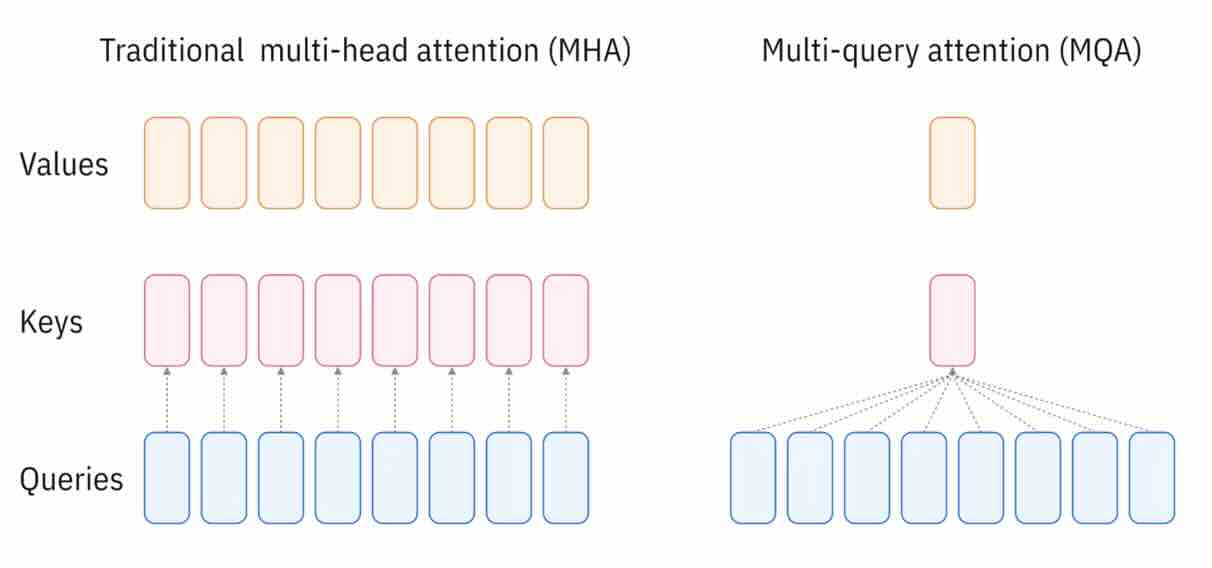

Схема: IBM. Метод: [Ainslie et al., 2023](https://arxiv.org/abs/2305.13245).

**Вопрос:** Почему не делаем для Q один и тот же вес?

#### Ответ:

Если сделать для Q один и тот же вес для всех голов, то мы лишимся многоголовости



#### Реализация MQA

In [ ]:
class MultiQueryAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        """
        Multi-Query Attention механизм
        В MQA: Q имеет несколько голов, но K и V имеют только одну голову

        Args:
            d_model: размерность модели (embedding dimension)
            num_heads: количество голов для Query
        """
        super(MultiQueryAttention, self).__init__()

        assert d_model % num_heads == 0, "d_model должен делиться на num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads  # размерность каждой головы Query

        # Линейные слои
        self.W_q = nn.Linear(d_model, d_model)  # Query: num_heads голов
        self.W_k = nn.Linear(d_model, self.d_k)  # Key: только одна голова
        self.W_v = nn.Linear(d_model, self.d_k)  # Value: только одна голова

        # Выходной линейный слой
        self.W_o = nn.Linear(d_model, d_model)

    def forward(self, query, key, value, mask=None):
        """
        Forward pass для Multi-Query Attention

        Args:
            query: тензор [batch_size, seq_len_q, d_model]
            key: тензор [batch_size, seq_len_k, d_model]
            value: тензор [batch_size, seq_len_v, d_model]
            mask: опциональная маска [batch_size, 1, seq_len_q, seq_len_k]

        Returns:
            output: тензор [batch_size, seq_len_q, d_model]
            attention_weights: тензор [batch_size, num_heads, seq_len_q, seq_len_k]
        """
        batch_size = query.size(0)
        seq_len_q = query.size(1)
        seq_len_k = key.size(1)

        # Query: применяем линейное преобразование и разбиваем на головы
        # [batch_size, seq_len_q, d_model] -> [batch_size, seq_len_q, num_heads, d_k]
        Q = self.W_q(query)
        Q = Q.view(batch_size, seq_len_q, self.num_heads, self.d_k)
        Q = Q.transpose(1, 2)  # [batch_size, num_heads, seq_len_q, d_k]

        # Key и Value: одна голова для всех
        # [batch_size, seq_len_k, d_model] -> [batch_size, seq_len_k, d_k]
        K = self.W_k(key)
        V = self.W_v(value)

        # Расширяем K и V для всех голов Query
        # [batch_size, seq_len_k, d_k] -> [batch_size, 1, seq_len_k, d_k] -> [batch_size, num_heads, seq_len_k, d_k]
        K = K.unsqueeze(1).expand(batch_size, self.num_heads, seq_len_k, self.d_k)
        V = V.unsqueeze(1).expand(batch_size, self.num_heads, seq_len_k, self.d_k)

        # Вычисляем scaled dot-product attention
        # scores: [batch_size, num_heads, seq_len_q, seq_len_k]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)

        # Применяем маску (если есть)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        # Применяем softmax
        attention_weights = torch.softmax(scores, dim=-1)

        # Умножаем на V: [batch_size, num_heads, seq_len_q, d_k]
        attn_output = torch.matmul(attention_weights, V)

        # Объединяем головы: [batch_size, seq_len_q, num_heads, d_k]
        attn_output = attn_output.transpose(1, 2).contiguous()

        # Reshape: [batch_size, seq_len_q, d_model]
        attn_output = attn_output.view(batch_size, seq_len_q, self.d_model)

        # Применяем финальную линейную трансформацию
        output = self.W_o(attn_output)

        return output, attention_weights


### GQA

MQA - позволяет снизить число параметров, но это слишком радикальное решение. Из-за этого качество модели может снизиться. Есть ли какое-то решение посередине?

$$
Q^h = \{q_i = X W_i^Q \in \mathbb{R}^{L \times d}\}_{i=1}^{h}
$$
$$
K^h = \{k_i = X W_i^K \in \mathbb{R}^{L \times d}\}_{i=1}^{h}
$$
$$
V^h = \{v_i = X W_i^V \in \mathbb{R}^{L \times d}\}_{i=1}^{h}
$$

Что если мы будем использовать не одни и те же веса для всех K, V, а разделим головы на группы и внутри одной группы будут одни и те же веса?

$G \in \{1, ..., h\}$ - число групп K/V, которое делит $h$. В каждой группе $h/G$ Query-голов.

$g(i)$ - функция, которая ставит в соответствие номер головы - номеру группы.

Например: $g(i) = 1 + \left\lfloor \frac{i-1}{h/G} \right\rfloor, \qquad i=1,\ldots,h$

Тогда разделим параметры между головами следующим образом:

$$
W_i^K := \bar{W}_{g(i)}^K, \forall i = 1,..., h
$$
$$
W_i^V := \bar{W}_{g(i)}^V, \forall i = 1,..., h
$$

Теперь в Q/K/V-проекциях без смещений обучаемых параметров: $D \times d \times (h + 2G)$. Вводится новый гиперпараметр $G$.

Такой подход называется Grouped Query Attention (GQA).

Рассмотрим краевые случаи:

1. $\mathbf{G = h}$: у каждой Query-головы своя группа K/V. Это MHA.

$$
g(i) = i
$$

$$
W_i^K = \bar{W}_{g(i)}^K = \bar{W}_{i}^K
$$


2. $G = 1$: одна группа K/V для всех Query-голов. Это MQA.

$$
g(i) = 1
$$

$$
W_i^K = \bar{W}_{g(i)}^K = \bar{W}_{1}^K
$$

Таким образом GQA - обобщение над MHA и MQA. Это более гибкая реализация, которая позволит разменивать скорость на качество через гиперпараметр.

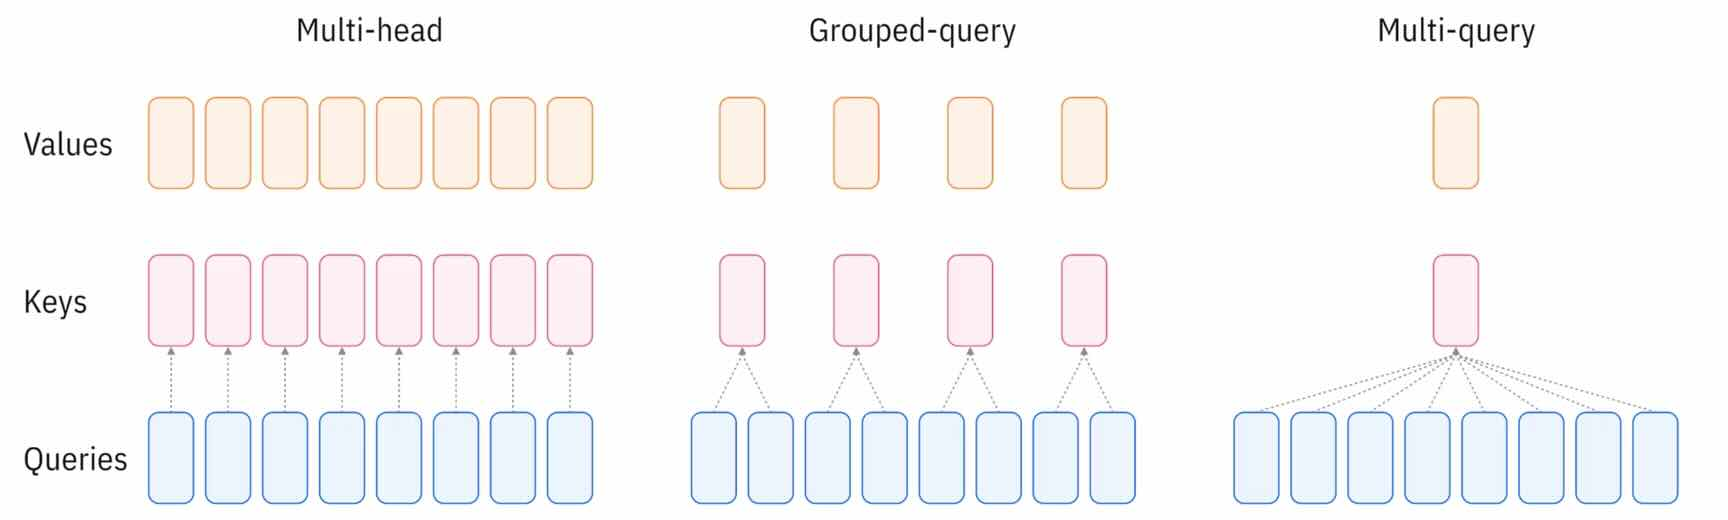

Схема: IBM. Метод: [Ainslie et al., 2023](https://arxiv.org/abs/2305.13245).

#### Реализация GQA

In [ ]:
class GroupedQueryAttention(nn.Module):
    def __init__(self, d_model, num_heads, num_kv_heads=None):
        """
        Grouped Query Attention механизм
        В GQA: Q имеет num_heads голов, K и V имеют num_kv_heads голов (num_kv_heads < num_heads)
        Каждая KV голова используется группой Query голов

        Args:
            d_model: размерность модели (embedding dimension)
            num_heads: количество голов для Query
            num_kv_heads: количество голов для Key и Value (по умолчанию num_heads // 2)
        """
        super(GroupedQueryAttention, self).__init__()

        assert d_model % num_heads == 0, "d_model должен делиться на num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.num_kv_heads = num_kv_heads if num_kv_heads is not None else num_heads // 2

        assert num_heads % self.num_kv_heads == 0, "num_heads должен делиться на num_kv_heads"
        assert self.num_kv_heads > 0, "num_kv_heads должен быть > 0"

        self.d_k = d_model // num_heads  # размерность каждой головы
        self.num_groups = num_heads // self.num_kv_heads  # количество Query голов на одну KV голову

        # Линейные слои
        self.W_q = nn.Linear(d_model, d_model)  # Query: num_heads голов
        self.W_k = nn.Linear(d_model, self.num_kv_heads * self.d_k)  # Key: num_kv_heads голов
        self.W_v = nn.Linear(d_model, self.num_kv_heads * self.d_k)  # Value: num_kv_heads голов

        # Выходной линейный слой
        self.W_o = nn.Linear(d_model, d_model)

    def forward(self, query, key, value, mask=None):
        """
        Forward pass для Grouped Query Attention

        Args:
            query: тензор [batch_size, seq_len_q, d_model]
            key: тензор [batch_size, seq_len_k, d_model]
            value: тензор [batch_size, seq_len_v, d_model]
            mask: опциональная маска [batch_size, 1, seq_len_q, seq_len_k]

        Returns:
            output: тензор [batch_size, seq_len_q, d_model]
            attention_weights: тензор [batch_size, num_heads, seq_len_q, seq_len_k]
        """
        batch_size = query.size(0)
        seq_len_q = query.size(1)
        seq_len_k = key.size(1)

        # Query: применяем линейное преобразование и разбиваем на num_heads голов
        # [batch_size, seq_len_q, d_model] -> [batch_size, num_heads, seq_len_q, d_k]
        Q = self.W_q(query)
        Q = Q.view(batch_size, seq_len_q, self.num_heads, self.d_k)
        Q = Q.transpose(1, 2)  # [batch_size, num_heads, seq_len_q, d_k]

        # Key и Value: применяем линейное преобразование и разбиваем на num_kv_heads голов
        # [batch_size, seq_len_k, d_model] -> [batch_size, num_kv_heads, seq_len_k, d_k]
        K = self.W_k(key)
        V = self.W_v(value)

        K = K.view(batch_size, seq_len_k, self.num_kv_heads, self.d_k)
        V = V.view(batch_size, seq_len_k, self.num_kv_heads, self.d_k)

        K = K.transpose(1, 2)  # [batch_size, num_kv_heads, seq_len_k, d_k]
        V = V.transpose(1, 2)  # [batch_size, num_kv_heads, seq_len_k, d_k]

        # Повторяем каждую KV голову num_groups раз для соответствующих Query голов
        # [batch_size, num_kv_heads, seq_len_k, d_k] -> [batch_size, num_heads, seq_len_k, d_k]
        K = K.repeat_interleave(self.num_groups, dim=1)
        V = V.repeat_interleave(self.num_groups, dim=1)

        # Вычисляем scaled dot-product attention
        # scores: [batch_size, num_heads, seq_len_q, seq_len_k]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)

        # Применяем маску (если есть)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        # Применяем softmax
        attention_weights = torch.softmax(scores, dim=-1)

        # Умножаем на V: [batch_size, num_heads, seq_len_q, d_k]
        attn_output = torch.matmul(attention_weights, V)

        # Объединяем головы: [batch_size, seq_len_q, num_heads, d_k]
        attn_output = attn_output.transpose(1, 2).contiguous()

        # Reshape: [batch_size, seq_len_q, d_model]
        attn_output = attn_output.view(batch_size, seq_len_q, self.d_model)

        # Применяем финальную линейную трансформацию
        output = self.W_o(attn_output)

        return output, attention_weights

### Сравнение MHA, MQA и GQA

Для одинаковых входов и числа Query-голов сравним формы K/V до повторения голов и число параметров. В исходной реализации MHA смещения отключены, а в MQA и GQA включены, поэтому считаем их отдельно. Считаем элементы K/V одного слоя; скорость и качество здесь не измеряются.


| Метод | KV-голов | Форма K и V | Веса | Смещения | Всего параметров | Чисел в K+V |
|:--|--:|:--|--:|--:|--:|--:|
| MHA | 8 | `(2, 8, 8, 8)` | 16384 | 0 | 16384 | 2048 |
| MQA | 1 | `(2, 1, 8, 8)` | 9216 | 144 | 9360 | 256 |
| GQA | 2 | `(2, 2, 8, 8)` | 10240 | 160 | 10400 | 512 |


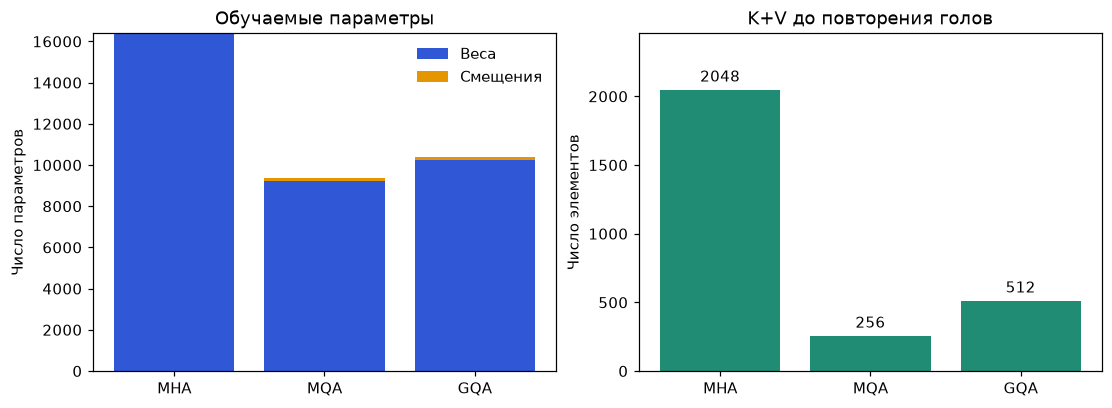

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.unicode_minus': False})

with torch.random.fork_rng(devices=[]):
    torch.manual_seed(7)
    demo_batch, demo_length, demo_width = 2, 8, 64
    demo_heads, demo_kv_heads = 8, 2
    demo_input = torch.randn(demo_batch, demo_length, demo_width)
    demo_variants = [
        ('MHA', MultiHeadAttention(demo_width, demo_heads), demo_heads),
        ('MQA', MultiQueryAttention(demo_width, demo_heads), 1),
        ('GQA', GroupedQueryAttention(demo_width, demo_heads, demo_kv_heads), demo_kv_heads),
    ]

attention_demo_rows = []
with torch.no_grad():
    for name, layer, kv_heads in demo_variants:
        head_dim = demo_width // demo_heads
        # K/V до расширения по Query-головам внутри forward.
        keys = layer.W_k(demo_input).view(demo_batch, demo_length, kv_heads, head_dim).transpose(1, 2)
        values = layer.W_v(demo_input).view(demo_batch, demo_length, kv_heads, head_dim).transpose(1, 2)
        output, attention = layer(demo_input, demo_input, demo_input)
        weights = sum(p.numel() for key, p in layer.named_parameters() if key.endswith('weight'))
        biases = sum(p.numel() for key, p in layer.named_parameters() if key.endswith('bias'))
        assert output.shape == demo_input.shape
        attention_demo_rows.append({
            'name': name, 'kv_heads': kv_heads, 'shape': tuple(keys.shape),
            'weights': weights, 'biases': biases, 'total': weights + biases,
            'kv_elements': keys.numel() + values.numel(),
        })

table = '| Метод | KV-голов | Форма K и V | Веса | Смещения | Всего параметров | Чисел в K+V |\n'
table += '|:--|--:|:--|--:|--:|--:|--:|\n'
for row in attention_demo_rows:
    table += (f"| {row['name']} | {row['kv_heads']} | `{row['shape']}` | "
              f"{row['weights']} | {row['biases']} | {row['total']} | {row['kv_elements']} |\n")
display(Markdown(table))

names = [row['name'] for row in attention_demo_rows]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout='constrained')
axes[0].bar(names, [row['weights'] for row in attention_demo_rows], label='Веса', color='#3057D5')
axes[0].bar(names, [row['biases'] for row in attention_demo_rows],
            bottom=[row['weights'] for row in attention_demo_rows], label='Смещения', color='#E59500')
axes[0].set_title('Обучаемые параметры')
axes[0].set_ylabel('Число параметров')
axes[0].legend(frameon=False)
bars = axes[1].bar(names, [row['kv_elements'] for row in attention_demo_rows], color='#218C74')
axes[1].bar_label(bars, padding=3)
axes[1].set_ylim(0, max(row['kv_elements'] for row in attention_demo_rows) * 1.2)
axes[1].set_title('K+V до повторения голов')
axes[1].set_ylabel('Число элементов')
plt.show()


## MoE

Посмотрим, что еще можно соптимизировать в трансформере.

**Вопрос:** Какая часть стандартного блока трансформера самая тяжелая по параметрам?

#### Ответ:

Самая тяжелая по весам часть стандартного блока трансформера - FFN. Она представляет из себя 2-слойную MLP: $2 \times D \times D_{FFN}$ параметров без учета смещений, где $D_{FFN}$ - ширина внутреннего слоя (например, $D_{FFN} = 4D$).

#### Как оптимизируем?

Как можно уменьшить число параметров?

Напрямую без потери качества - почти никак.

Подумаем немного в обратную сторону - допустим, мы можем себе позволить много памяти. Можем ли мы использовать больше памяти, но при этом быстро инферить модели? В теории хотим так, чтобы модель была быстрой, но при этом умной, а цена, которую мы за это заплатим - память (RAM).

Есть подход, который подходит к данной проблеме - Mixture of Experts (MoE)

Предлагается обучать несколько голов FFN, но использовать не все, а только необходимые. Так мы будем хранить много весов, но использовать их эффективно (в теории). Здесь MoE реализован очень наивно, чтобы была понятна суть метода.

#### Expert

Давайте попробуем применить такой же трюк, как в Attention - сделаем несколько голов (назовем их **экспертами**).

**Эксперт** - обычная FFN.

In [ ]:
class Expert(nn.Module):
    """Один эксперт - стандартная feed-forward сеть"""
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.w1 = nn.Linear(d_model, d_ff)
        self.w2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # FFN: W2(dropout(gelu(W1(x))))
        return self.w2(self.dropout(F.gelu(self.w1(x))))

#### Router

Для ускорения инференса, мы не будем использовать все головы, а только часть. Чтобы понять, каких экспертов используем, будем обучать отдельную модель, которую мы назовем **router**. Этот модуль будет предсказывать, каких экспертов для выбранного токена нужно использовать.

В целях экономии памяти, в качестве router мы возьмем обычную линейную модель. Выберем экспертов с наибольшими вероятностями при помощи top-k.

In [ ]:
class TopKRouter(nn.Module):
    """Роутер для выбора top-K экспертов"""
    def __init__(self, d_model, num_experts, top_k, capacity_factor=1.0):
        super().__init__()
        self.num_experts = num_experts
        self.top_k = top_k
        self.capacity_factor = capacity_factor

        # Gating network - простой линейный слой
        self.gate = nn.Linear(d_model, num_experts)

    def forward(self, x):
        """
        Args:
            x: [batch_size, seq_len, d_model]
        Returns:
            router_weights: [batch_size, seq_len, top_k]
            selected_experts: [batch_size, seq_len, top_k]
        """
        batch_size, seq_len, d_model = x.shape

        # Вычисляем веса для всех экспертов
        logits = self.gate(x)  # [batch, seq_len, num_experts]

        # Применяем softmax для получения вероятностей
        router_probs = F.softmax(logits, dim=-1)

        # Выбираем top-k экспертов
        router_weights, selected_experts = torch.topk(
            router_probs, self.top_k, dim=-1
        )

        # Нормализуем веса выбранных экспертов
        router_weights = router_weights / router_weights.sum(dim=-1, keepdim=True)

        return router_weights, selected_experts

#### MoE

Теперь соберем все вместе. Для каждого токена прогоняем через роутер, чтобы решить через каких экспертов он должен пройти, и используем только выбранных экспертов.

Данная реализация недостаточно эффективная, в идеале нужно итерироваться по экспертам, но в качестве демонстрации рассмотрим такую версию:


In [ ]:
class MoELayer(nn.Module):
    """Mixture of Experts layer"""
    def __init__(self, d_model, d_ff, num_experts=8, top_k=2, dropout=0.1):
        super().__init__()
        self.num_experts = num_experts
        self.top_k = top_k

        # Создаем экспертов
        self.experts = nn.ModuleList([
            Expert(d_model, d_ff, dropout) for _ in range(num_experts)
        ])

        # Роутер
        self.router = TopKRouter(d_model, num_experts, top_k)

    def forward(self, x):
        """
        Args:
            x: [batch_size, seq_len, d_model]
        Returns:
            output: [batch_size, seq_len, d_model]
        """
        batch_size, seq_len, d_model = x.shape

        # Получаем веса и индексы выбранных экспертов
        router_weights, selected_experts = self.router(x)
        # router_weights: [batch, seq_len, top_k]
        # selected_experts: [batch, seq_len, top_k]

        # Инициализируем выходной тензор
        output = torch.zeros_like(x)

        # Простая реализация: обрабатываем каждый токен отдельно
        # (в production используются более эффективные методы)
        for batch_idx in range(batch_size):
            for seq_idx in range(seq_len):
                token = x[batch_idx, seq_idx:seq_idx+1]  # [1, d_model]

                # Обрабатываем выбранными экспертами
                for k in range(self.top_k):
                    expert_idx = selected_experts[batch_idx, seq_idx, k].item()
                    weight = router_weights[batch_idx, seq_idx, k]

                    expert_output = self.experts[expert_idx](token)
                    output[batch_idx, seq_idx] += weight * expert_output.squeeze(0)

        return output

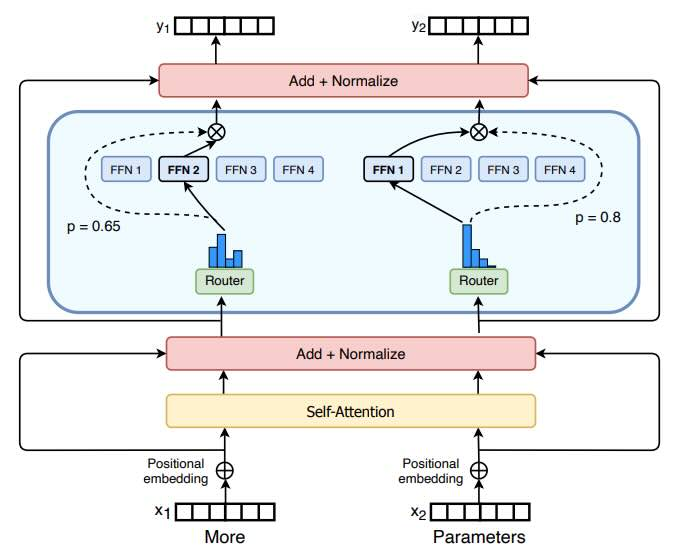

Схема: Hugging Face. Метод: [Jiang et al., 2024](https://arxiv.org/abs/2401.04088).

На схеме выбран один эксперт на токен; в демонстрации ниже используется `top_k=2`.

### Выбор экспертов

На случайных входах покажем выбранных экспертов, нормированные веса и число назначений каждому эксперту. Роутер и эксперты инициализированы случайно и не обучались. Для первого токена отдельно проверим взвешенную сумму выходов выбранных экспертов.


Вход: (1, 6, 16); выход: (1, 6, 16)


| Токен | Выбранные эксперты и нормированные веса |
|:--|:--|
| t0 | E2: 0.537, E0: 0.463 |
| t1 | E1: 0.524, E0: 0.476 |
| t2 | E0: 0.578, E1: 0.422 |
| t3 | E1: 0.681, E0: 0.319 |
| t4 | E1: 0.673, E3: 0.327 |
| t5 | E2: 0.588, E0: 0.412 |


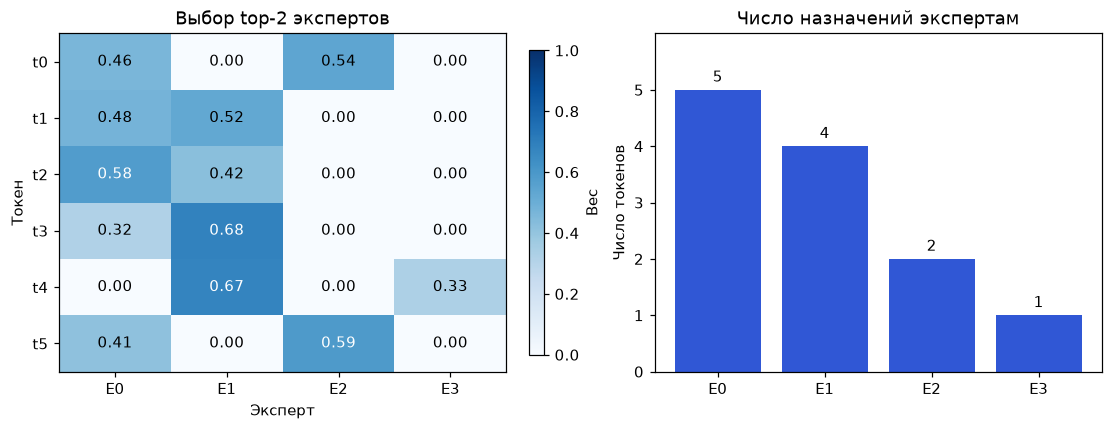

In [ ]:
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(17)
    moe_tokens = torch.randn(1, 6, 16)
    demo_experts, demo_top_k = 4, 2
    demo_moe = MoELayer(16, 32, num_experts=demo_experts, top_k=demo_top_k, dropout=0).eval()

with torch.no_grad():
    selected_weights, selected_experts = demo_moe.router(moe_tokens)
    moe_output = demo_moe(moe_tokens)
    routing_map = torch.zeros(moe_tokens.shape[1], demo_experts)
    routing_map.scatter_(1, selected_experts[0], selected_weights[0])
    first_token_sum = sum(
        selected_weights[0, 0, k] * demo_moe.experts[selected_experts[0, 0, k].item()](moe_tokens[0, 0])
        for k in range(demo_top_k)
    )
assert torch.allclose(routing_map.sum(dim=1), torch.ones(moe_tokens.shape[1]))
assert torch.allclose(moe_output[0, 0], first_token_sum, atol=1e-6)
print(f'Вход: {tuple(moe_tokens.shape)}; выход: {tuple(moe_output.shape)}')

table = '| Токен | Выбранные эксперты и нормированные веса |\n|:--|:--|\n'
for t in range(moe_tokens.shape[1]):
    routes = ', '.join(
        f'E{selected_experts[0, t, k].item()}: {selected_weights[0, t, k].item():.3f}'
        for k in range(demo_top_k)
    )
    table += f'| t{t} | {routes} |\n'
display(Markdown(table))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
image = axes[0].imshow(routing_map.numpy(), cmap='Blues', vmin=0, vmax=1, aspect='auto')
axes[0].set_xticks(range(demo_experts), [f'E{i}' for i in range(demo_experts)])
axes[0].set_yticks(range(moe_tokens.shape[1]), [f't{i}' for i in range(moe_tokens.shape[1])])
axes[0].set_title(f'Выбор top-{demo_top_k} экспертов')
axes[0].set_xlabel('Эксперт')
axes[0].set_ylabel('Токен')
for t in range(moe_tokens.shape[1]):
    for e in range(demo_experts):
        value = routing_map[t, e].item()
        axes[0].text(e, t, f'{value:.2f}', ha='center', va='center',
                     color='white' if value > 0.55 else 'black')
fig.colorbar(image, ax=axes[0], label='Вес', shrink=0.9)
expert_load = torch.bincount(selected_experts.flatten(), minlength=demo_experts)
bars = axes[1].bar([f'E{i}' for i in range(demo_experts)], expert_load.numpy(), color='#3057D5')
axes[1].bar_label(bars, padding=3)
axes[1].set_ylim(0, max(1, expert_load.max().item()) + 1)
axes[1].set_yticks(range(expert_load.max().item() + 1))
axes[1].set_title('Число назначений экспертам')
axes[1].set_ylabel('Число токенов')
plt.show()


### Выводы по методу

Основные сложности метода:
1. Неравномерная нагрузка на экспертов: через некоторых экспертов может проходить больше токенов, из-за этого некоторые эксперты могут недообучиться
2. MoE очень тяжело обучать из-за дискретизации на этапе выбора top-k.
3. В теории эксперты могут специализироваться на разных доменах, но на практике специализация не очевидна

MoE - отдельный мир, такие модели требуют тонкого подхода балансировки голов, подбора данных и гиперпараметров.

## Позиционное кодирование

**Вопрос:** Зачем нужен Positional Encoding?

#### Ответ:

 В attention никак не учитывается информация о позиции токенов, мы просто считаем веса для токенов в контексте. Поэтому мы добавляем к эмбеддингам информацию по позиции токена. PE необходим в подсчете весов attention.

### RoPE

Мы хотим, чтобы attention между токенами на позициях $m$ и $n$ зависел **только от относительной позиции** $n - m$, а не от абсолютных позиций.

Формально, мы хотим, чтобы для query $\mathbf{q}$ на позиции $m$ и key $\mathbf{k}$ на позиции $n$ выполнялось такое свойство:

$$\langle f_q(\mathbf{q}, m), f_k(\mathbf{k}, n) \rangle = g(\mathbf{q}, \mathbf{k}, n-m)$$

где $f_q$ и $f_k$ - функции, добавляющие позиционную информацию.

**Вопрос:** У какой функции есть похожие свойства?

$$\overline{f(x)}\,f(y) = f(y-x)$$

Подсказка: вспомните как работает скалярное произведение для комплексных чисел

#### Ответ:

$e^{ix}$

#### Двумерный случай

Представим 2D вектор как комплексное число:
$$\mathbf{q} = \begin{pmatrix} q_0 \\ q_1 \end{pmatrix} \leftrightarrow q_0 + iq_1$$

**Идея**: Умножение на комплексное число $e^{i\theta}$ - это поворот на угол $\theta$:

$$e^{i\theta} = \cos\theta + i\sin\theta$$

Определим:
$$f(\mathbf{q}, m) = \mathbf{q} e^{im\theta}$$

где $\theta$ - некоторая частота.

Проверим необходимое нам свойство:

$$\langle f(\mathbf{q}, m), f(\mathbf{k}, n) \rangle = \langle \mathbf{q} e^{im\theta}, \mathbf{k} e^{in\theta} \rangle$$

$$= \text{Re}(\mathbf{q}^* e^{-im\theta} \cdot \mathbf{k} e^{in\theta})$$

$$= \text{Re}(\mathbf{q}^* \mathbf{k} \cdot e^{i(n-m)\theta})$$

$$= \langle \mathbf{q}, \mathbf{k} e^{i(n-m)\theta} \rangle$$

**Вывод**: Зависит только от разности $n - m$!

В матричном виде поворот на угол $m\theta$:

$$f(\mathbf{q}, m) = \begin{pmatrix} \cos(m\theta) & -\sin(m\theta) \\ \sin(m\theta) & \cos(m\theta) \end{pmatrix} \begin{pmatrix} q_0 \\ q_1 \end{pmatrix}$$

Обозначим матрицу поворота как $\mathbf{R}^{(2)}_{\theta, m}$.

#### Обобщение на высокие размерности

Для $d$-мерного вектора ($d$ четное), разбиваем его на $d/2$ пар:

$$\mathbf{q} = \begin{pmatrix} q_0, q_1, q_2, q_3, \ldots, q_{d-2}, q_{d-1} \end{pmatrix}$$
$$\downarrow$$
$$\begin{pmatrix} (q_0, q_1), (q_2, q_3), \ldots, (q_{d-2}, q_{d-1}) \end{pmatrix}$$

#### Вращения с разными частотами

К каждой паре применяем свой угол поворота:

- Пара $(q_0, q_1)$: угол $m\theta_0$
- Пара $(q_2, q_3)$: угол $m\theta_1$
- ...
- Пара $(q_{d-2}, q_{d-1})$: угол $m\theta_{d/2-1}$

По аналогии с sinusoidal PE:

$$\theta_i = \frac{1}{10000^{2i/d}}, \quad i = 0, 1, \ldots, \frac{d}{2} - 1$$

или в более общем виде:

$$\theta_i = b^{-2i/d}$$

где $b = 10000$ (base).

Полная матрица поворота:

$$\mathbf{R}_{\Theta, m} = \begin{pmatrix}
\cos(m\theta_0) & -\sin(m\theta_0) & 0 & 0 & 0 & 0 & \cdots \\
\sin(m\theta_0) & \cos(m\theta_0) & 0 & 0 & 0 & 0 & \cdots \\
0 & 0 & \cos(m\theta_1) & -\sin(m\theta_1) & 0 & 0 & \cdots \\
0 & 0 & \sin(m\theta_1) & \cos(m\theta_1) & 0 & 0 & \cdots \\
0 & 0 & 0 & 0 & \cos(m\theta_2) & -\sin(m\theta_2) & \cdots \\
0 & 0 & 0 & 0 & \sin(m\theta_2) & \cos(m\theta_2) & \cdots \\
\vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \ddots
\end{pmatrix}$$

Это **блочно-диагональная** матрица с $d/2$ блоками размера $2 \times 2$.

#### Применение к Query и Key

Для токена на позиции $m$:

$$\tilde{\mathbf{q}}_m = \mathbf{R}_{\Theta, m} \mathbf{W}_q \mathbf{x}_m$$
$$\tilde{\mathbf{k}}_n = \mathbf{R}_{\Theta, n} \mathbf{W}_k \mathbf{x}_n$$

где $\mathbf{W}_q, \mathbf{W}_k$ - обычные проекционные матрицы.

$$\text{score}(m, n) = \tilde{\mathbf{q}}_m^\top \tilde{\mathbf{k}}_n = (\mathbf{R}_{\Theta, m} \mathbf{q}_m)^\top (\mathbf{R}_{\Theta, n} \mathbf{k}_n)$$

$$= \mathbf{q}_m^\top \mathbf{R}_{\Theta, m}^\top \mathbf{R}_{\Theta, n} \mathbf{k}_n$$

Матрицы вращения обладают свойством:

$$\mathbf{R}_{\Theta, m}^\top \mathbf{R}_{\Theta, n} = \mathbf{R}_{\Theta, n-m}$$

Тогда для score получаем такой результат:

$$\text{score}(m, n) = \mathbf{q}_m^\top \mathbf{R}_{\Theta, n-m} \mathbf{k}_n$$

Есть такая геометрическая интерпретация:

Каждая пара измерений образует "частотный канал":
- Малые индексы $i$: высокие частоты и быстрые вращения.
- Большие индексы $i$: низкие частоты и медленные вращения.

Метод называется **RoPE** он был описан в статье **RoFormer: Enhanced Transformer with Rotary Position Embedding** [Su et al., 2021](https://arxiv.org/abs/2104.09864).

RoPE применяет **те же частоты** что и в классическом PE, но через вращение вместо сложения!


#### Код RoPE + MHA

Матрица $\mathbf{R}_{\Theta, m}$ имеет размер $d \times d$, умножение $O(d^2)$.

Вместо матричного умножения используем **поэлементные операции**:

$$\mathbf{R}_{\Theta, m} \mathbf{q} = \begin{pmatrix}
q_0 \cos(m\theta_0) - q_1 \sin(m\theta_0) \\
q_0 \sin(m\theta_0) + q_1 \cos(m\theta_0) \\
q_2 \cos(m\theta_1) - q_3 \sin(m\theta_1) \\
q_2 \sin(m\theta_1) + q_3 \cos(m\theta_1) \\
\vdots
\end{pmatrix}$$

Определим:
- $\mathbf{q}^{(1)} = [q_0, q_1, q_2, q_3, \ldots]$
- $\mathbf{q}^{(2)} = [-q_1, q_0, -q_3, q_2, \ldots]$
- $\boldsymbol{\cos} = [\cos(m\theta_0), \cos(m\theta_0), \cos(m\theta_1), \cos(m\theta_1), \ldots]$
- $\boldsymbol{\sin} = [\sin(m\theta_0), \sin(m\theta_0), \sin(m\theta_1), \sin(m\theta_1), \ldots]$

Тогда:

$$\mathbf{R}_{\Theta, m} \mathbf{q} = \mathbf{q}^{(1)} \odot \boldsymbol{\cos} + \mathbf{q}^{(2)} \odot \boldsymbol{\sin}$$

**Сложность**: $O(d)$ вместо $O(d^2)$

In [ ]:
class RotaryPositionEmbedding(nn.Module):
    """
    RoPE (Rotary Position Embedding)

    Применяет вращения к query и key векторам для кодирования позиционной информации.
    """
    def __init__(self, dim, max_seq_len=2048, base=10000, device=None):
        """
        Args:
            dim: Размерность эмбеддингов (должна быть четной)
            max_seq_len: Максимальная длина последовательности
            base: База для вычисления частот (обычно 10000)
            device: Устройство (cpu/cuda)
        """
        super().__init__()
        assert dim % 2 == 0, "Размерность должна быть четной"

        self.dim = dim
        self.max_seq_len = max_seq_len
        self.base = base

        # Предвычисляем частоты theta_i = base^(-2i/d)
        inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
        self.register_buffer('inv_freq', inv_freq)

        # Предвычисляем cos и sin для всех позиций
        self._build_cache(max_seq_len, device)

    def _build_cache(self, max_seq_len, device=None):
        """Предвычисляет cos и sin для всех позиций"""
        # Позиции: [0, 1, 2, ..., max_seq_len-1]
        t = torch.arange(max_seq_len, device=device, dtype=self.inv_freq.dtype)

        # Вычисляем m * theta_i для всех позиций m и частот theta_i
        # freqs: (max_seq_len, dim/2)
        freqs = torch.outer(t, self.inv_freq)

        # Дублируем для пар: [theta_0, theta_0, theta_1, theta_1, ...]
        # emb: (max_seq_len, dim)
        emb = torch.repeat_interleave(freqs, 2, dim=-1)

        # Вычисляем cos и sin
        self.register_buffer('cos_cached', emb.cos()[None, None, :, :], persistent=False)
        self.register_buffer('sin_cached', emb.sin()[None, None, :, :], persistent=False)

    def _rotate_half(self, x):
        """
        Поворачивает половину скрытых измерений.

        Для вектора [q0, q1, q2, q3, q4, q5, ...]
        возвращает    [-q1, q0, -q3, q2, -q5, q4, ...]
        Это эквивалентно умножению на sin в формуле вращения.
        """
        x1 = x[..., ::2]   # [q0, q2, q4, ...]
        x2 = x[..., 1::2]  # [q1, q3, q5, ...]

        # Чередуем: [-q1, q0, -q3, q2, ...]
        x_rotated = torch.stack([-x2, x1], dim=-1)
        x_rotated = x_rotated.flatten(-2)

        return x_rotated

    def forward(self, q, k, seq_len=None):
        """
        Применяет RoPE к query и key тензорам.

        Args:
            q: Query тензор (batch_size, num_heads, seq_len, head_dim)
            k: Key тензор (batch_size, num_heads, seq_len, head_dim)
            seq_len: Длина последовательности (если None, берется из q)

        Returns:
            q_rotated, k_rotated: Повернутые query и key
        """
        if seq_len is None:
            seq_len = q.shape[2]

        # Берем нужное количество предвычисленных значений
        cos = self.cos_cached[:, :, :seq_len, :]
        sin = self.sin_cached[:, :, :seq_len, :]

        # Применяем вращение: q * cos + rotate_half(q) * sin
        q_rotated = (q * cos) + (self._rotate_half(q) * sin)
        k_rotated = (k * cos) + (self._rotate_half(k) * sin)

        return q_rotated, k_rotated


class RoPEAttention(nn.Module):
    """
    Multi-head attention с RoPE
    """
    def __init__(self, d_model, num_heads, max_seq_len=2048):
        super().__init__()
        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        # Проекции
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        # RoPE
        self.rope = RotaryPositionEmbedding(self.d_k, max_seq_len)

    def forward(self, x, mask=None):
        """
        Args:
            x: (batch_size, seq_len, d_model)
            mask: optional (batch_size, 1, seq_len, seq_len)
        """
        batch_size, seq_len, _ = x.shape

        Q = self.W_q(x).view(batch_size, seq_len, self.num_heads, self.d_k)
        K = self.W_k(x).view(batch_size, seq_len, self.num_heads, self.d_k)
        V = self.W_v(x).view(batch_size, seq_len, self.num_heads, self.d_k)

        Q = Q.transpose(1, 2)
        K = K.transpose(1, 2)
        V = V.transpose(1, 2)

        # =========== Применяем RoPE к Q и K ===========
        Q, K = self.rope(Q, K, seq_len)
        # ==============================================

        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)

        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))

        attn = torch.softmax(scores, dim=-1)

        output = torch.matmul(attn, V)

        output = output.transpose(1, 2).contiguous().view(batch_size, seq_len, self.d_model)

        output = self.W_o(output)

        return output, attn

### Вращение и относительная позиция

В двумерном примере RoPE вращает вектор q, сохраняя его норму. Затем сравним скалярные произведения при исходных позициях и после одинакового сдвига позиций q и k. Векторы до вращения фиксированы, поэтому график показывает влияние позиционного преобразования.


Максимальное изменение нормы q: 5.96e-08
Максимальное изменение скалярного произведения при общем сдвиге: 1.19e-07


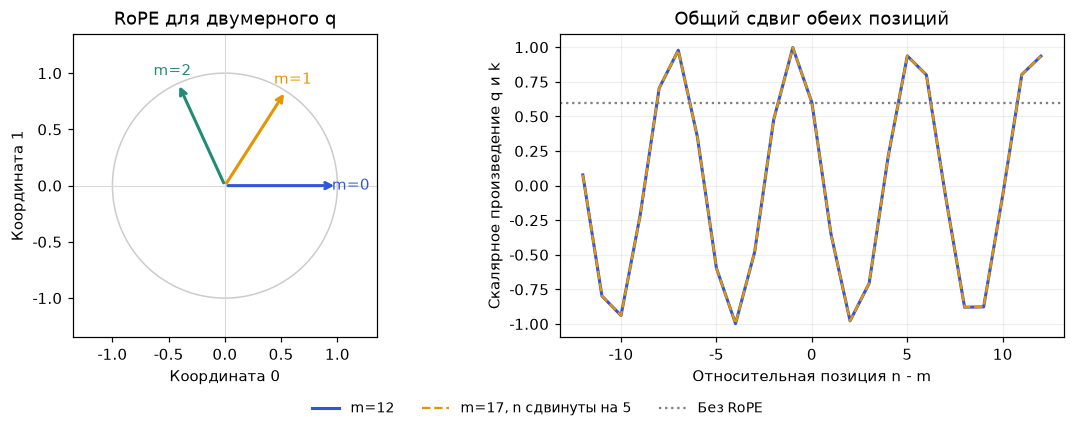

In [ ]:
demo_rope = RotaryPositionEmbedding(dim=2, max_seq_len=64)
base_query = torch.tensor([1.0, 0.0])
base_key = torch.tensor([0.6, 0.8])
positions_count = 40
queries = base_query.view(1, 1, 1, 2).repeat(1, 1, positions_count, 1)
keys = base_key.view(1, 1, 1, 2).repeat(1, 1, positions_count, 1)
rotated_queries, rotated_keys = demo_rope(queries, keys)

query_position, common_shift = 12, 5
key_positions = torch.arange(25)
relative_positions = key_positions - query_position
base_scores = rotated_keys[0, 0, key_positions] @ rotated_queries[0, 0, query_position]
shifted_scores = (rotated_keys[0, 0, key_positions + common_shift]
                  @ rotated_queries[0, 0, query_position + common_shift])
norm_error = (rotated_queries.norm(dim=-1) - queries.norm(dim=-1)).abs().max().item()
shift_error = (base_scores - shifted_scores).abs().max().item()
assert torch.allclose(rotated_queries.norm(dim=-1), queries.norm(dim=-1), atol=1e-6)
assert torch.allclose(base_scores, shifted_scores, atol=2e-6)
print(f'Максимальное изменение нормы q: {norm_error:.2e}')
print(f'Максимальное изменение скалярного произведения при общем сдвиге: {shift_error:.2e}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
circle = torch.linspace(0, 2 * math.pi, 200)
axes[0].plot(circle.cos(), circle.sin(), color='0.8', linewidth=1)
for pos, color in zip([0, 1, 2], ['#3057D5', '#E59500', '#218C74']):
    vector = rotated_queries[0, 0, pos].numpy()
    axes[0].annotate('', xy=vector, xytext=(0, 0),
                     arrowprops={'arrowstyle': '->', 'color': color, 'lw': 2})
    axes[0].text(vector[0] * 1.12, vector[1] * 1.12, f'm={pos}', color=color,
                 ha='center', va='center')
axes[0].axhline(0, color='0.85', linewidth=0.7)
axes[0].axvline(0, color='0.85', linewidth=0.7)
axes[0].set(xlim=(-1.35, 1.35), ylim=(-1.35, 1.35), aspect='equal',
             title='RoPE для двумерного q', xlabel='Координата 0', ylabel='Координата 1')
axes[1].plot(relative_positions.numpy(), base_scores.numpy(), color='#3057D5',
              linewidth=2, label=f'm={query_position}')
axes[1].plot(relative_positions.numpy(), shifted_scores.numpy(), color='#E59500',
              linestyle='--', label=f'm={query_position + common_shift}, n сдвинуты на {common_shift}')
axes[1].axhline((base_query @ base_key).item(), color='0.5', linestyle=':', label='Без RoPE')
axes[1].set_title('Общий сдвиг обеих позиций')
axes[1].set_xlabel('Относительная позиция n - m')
axes[1].set_ylabel('Скалярное произведение q и k')
fig.legend(loc='outside lower center', ncol=3, frameon=False, fontsize=9)
axes[1].grid(alpha=0.2)
plt.show()


## Источники

[Исходный материал](https://github.com/mmp-practicum-team/mmp_dl_spring_2025)

- **BERT**: [Devlin J. et al., 2019](https://arxiv.org/abs/1810.04805)
- **RoBERTa**: [Liu Y. et al., 2019](https://arxiv.org/abs/1907.11692)
- **DistilBERT**: [Sanh V. et al., 2020](https://arxiv.org/abs/1910.01108)